# **RETAIL SALES ANALYSIS**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import seaborn.objects as so

In [ ]:
customers=pd.read_csv(r"/content/customers (1).csv")
orders=pd.read_csv(r"/content/orders (1).csv")
products=pd.read_csv(r"/content/products (1).csv")

In [ ]:
tables={
    "customers":customers,
    "orders":orders,
    "products":products}

# **columns of tables**

In [ ]:
for name,df in tables.items():
   print(name.upper())
   print(df.columns)
   print("\n")

CUSTOMERS
Index(['customer_id', 'gender', 'age', 'city', 'signup_date',
       'loyalty_member'],
      dtype='object')


ORDERS
Index(['order_id', 'customer_id', 'product_id', 'order_date', 'quantity',
       'payment_method'],
      dtype='object')


PRODUCTS
Index(['product_id', 'product_name', 'category', 'price'], dtype='object')




# **shape of tables**

In [ ]:
for name,df in tables.items():
    print(name, ":",df.shape)

customers : (1200, 6)
orders : (4000, 6)
products : (80, 4)


# **data information**

In [ ]:
for name,df in tables.items():
    print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customer_id     1200 non-null   object
 1   gender          1200 non-null   object
 2   age             1200 non-null   int64 
 3   city            1200 non-null   object
 4   signup_date     1200 non-null   object
 5   loyalty_member  1200 non-null   object
dtypes: int64(1), object(5)
memory usage: 56.4+ KB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   order_id        4000 non-null   object
 1   customer_id     4000 non-null   object
 2   product_id      4000 non-null   object
 3   order_date      4000 non-null   object
 4   quantity        4000 non-null   int64 
 5   payment_method  4000 non-null   object
dtypes: int64(1), object(5)


# **duplicates**  
- check duplicates-`duplicated().sum()`  
- remove duplicates-`drop_duplicates(inplace=True)`


In [ ]:
#check duplicates
for name,df in tables.items():
   print(name, ":" ,(df.duplicated()).sum())

customers : 0
orders : 0
products : 0


In [ ]:
# remove duplicates
for name,df in tables.items():
    tables[name] = df.drop_duplicates()
    # if we use   inplace=True - it changes original dataframe


# **Missing values**
-check missing values-`isnull().sum()`      
-delete  - `dropna()`    
-fill- `fillna()` (using mean, median or mode)   

In [ ]:
for name,df in tables.items():
    print(df.isnull().sum())

customer_id       0
gender            0
age               0
city              0
signup_date       0
loyalty_member    0
dtype: int64
order_id          0
customer_id       0
product_id        0
order_date        0
quantity          0
payment_method    0
dtype: int64
product_id      0
product_name    0
category        0
price           0
dtype: int64


In [ ]:
for name,df in tables.items():
    print(name,":",df.isnull().sum().sum())

customers : 0
orders : 0
products : 0


In [ ]:
# Mean (Numerical)
customers["age"] = customers["age"].fillna(customers["age"].mean())

# Median (Numerical)
products["price"] = products["price"].fillna(products["price"].median())

# Mode (Categorical) — mode() returns a Series, so take [0]
customers["city"] = customers["city"].fillna(customers["city"].mode()[0])
orders["payment_method"] = orders["payment_method"].fillna(orders["payment_method"].mode()[0])

#**Datatype conversion**  
`astype`

**customers_table**  
0   customer_id     1200 non-null   object  -->  values contain letters  
 1   gender          1200 non-null   object  -->  category  
 2   age             1200 non-null   int64   
 3   city            1200 non-null   object  -->  category  
 4   signup_date     1200 non-null   object  -->  datetime64  
 5   loyalty_member  1200 non-null   object  -->  category  
**orders_table**  
  0   order_id        4000 non-null   object  --> values contain letters   
 1   customer_id     4000 non-null   object  -->  values contain letters  
 2   product_id      4000 non-null   object  -->  values contain letters  
 3   order_date      4000 non-null   object  -->  datetime64  
 4   quantity        4000 non-null   int64   
 5   payment_method  4000 non-null   object  -->  category   
**products_table**  
 0   product_id    80 non-null     object   -->  values contain letters  
 1   product_name  80 non-null     object   
 2   category      80 non-null     object   -->  category  
 3   price         80 non-null     float64   

In [ ]:
tables["customers"][["gender","city","loyalty_member"]]=tables["customers"][["gender","city","loyalty_member"]].astype("category")
tables["customers"]["signup_date"]=pd.to_datetime(tables["customers"]["signup_date"])



In [ ]:
tables["orders"]["order_date"]=pd.to_datetime(tables["orders"]["order_date"])
tables["orders"]["payment_method"]=tables["orders"]["payment_method"].astype("category")

In [ ]:
tables["products"]["category"]=tables["products"]["category"].astype("category")


In [ ]:
for name,df in tables.items():
    print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customer_id     1200 non-null   object        
 1   gender          1200 non-null   category      
 2   age             1200 non-null   int64         
 3   city            1200 non-null   category      
 4   signup_date     1200 non-null   datetime64[ns]
 5   loyalty_member  1200 non-null   category      
dtypes: category(3), datetime64[ns](1), int64(1), object(1)
memory usage: 32.4+ KB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        4000 non-null   object        
 1   customer_id     4000 non-null   object        
 2   product_id      4000 non-null   object        
 3   order_date      400

# **EDA**-**EXPLORATORY DATA ANALYSIS**

# Univariate Analysis  

Customer age distribution   
Gender distribution          
City distribution          
Loyalty-member distribution   
Order quantity distribution      
Payment-method distribution      
Product-category distribution   
Product-price distribution  

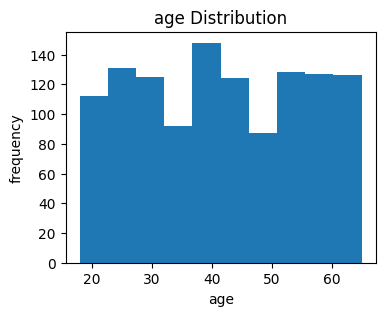

In [ ]:
plt.figure(figsize=(4,3))
plt.hist(customers['age'])
plt.xlabel('age')
plt.ylabel('frequency')
plt.title('age Distribution')
plt.show()

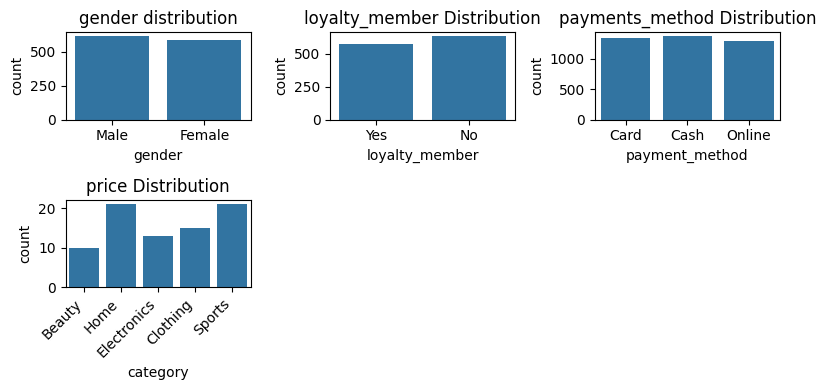

In [ ]:
#category data
plt.figure(figsize=(8,4))

plt.subplot(2,3,1)
sns.countplot(data=customers ,x='gender')
plt.title('gender distribution')

plt.subplot(2,3,2)
sns.countplot(data=customers ,x='loyalty_member')
plt.title('loyalty_member Distribution')

plt.subplot(2,3,3)
sns.countplot(data=orders ,x='payment_method')
plt.title('payments_method Distribution')

plt.subplot(2,3,4)
sns.countplot(data=products,x='category')
plt.title('price Distribution')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()


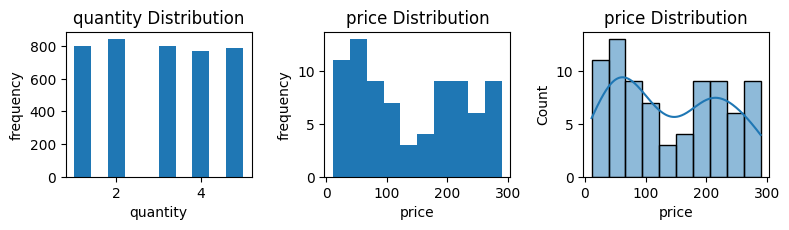

In [ ]:
# numeric data
plt.figure(figsize=(8,4))
plt.subplot(2,3,1)
plt.hist(orders['quantity'])
plt.xlabel('quantity')
plt.ylabel('frequency')
plt.title('quantity Distribution')

plt.subplot(2,3,2)
plt.hist(products['price'])
plt.xlabel('price')
plt.ylabel('frequency')
plt.title('price Distribution')

plt.subplot(2,3,3)
sns.histplot(data=products,x='price',bins=10,kde=True)
plt.title('price Distribution')


plt.tight_layout()
plt.show()

# Bivariate Analysis

Age vs gender  
Age vs loyalty membership  
City vs number of orders  
Payment method vs order quantity  
Product category vs price  
Product category vs quantity sold  
Loyalty membership vs number of orders  

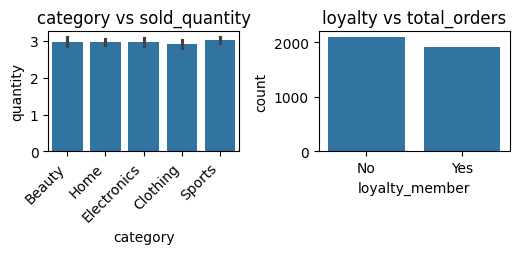

In [ ]:
orders_products=orders.merge(products,on='product_id')
orders_customers=orders.merge(customers,on='customer_id')
plt.figure(figsize=(8,4))

plt.subplot(2,3,1)
sns.barplot(data=orders_products,x='category',y='quantity')
plt.title('category vs sold_quantity')
plt.xticks(rotation=45,ha='right')

plt.subplot(2,3,2)
sns.countplot(data=orders_customers,x='loyalty_member')
plt.title('loyalty vs total_orders')

plt.tight_layout()
plt.show()

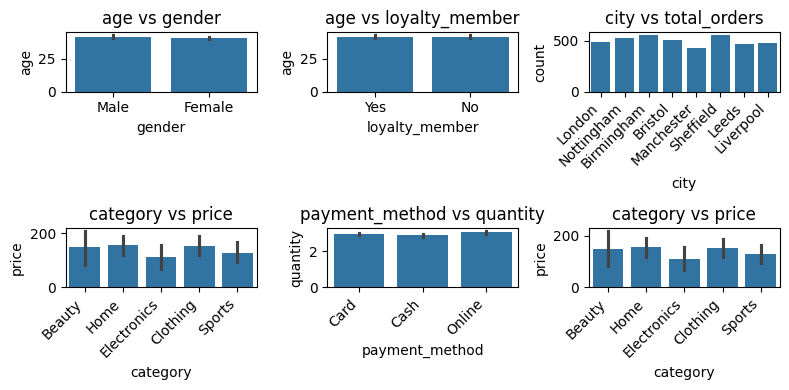

In [ ]:
 orders_customers= orders.merge(customers, on='customer_id')

 plt.figure(figsize=(8,4))

 plt.subplot(2,3,1)
 sns.barplot(data=customers ,x='gender',y='age')
 plt.title('age vs gender')

 plt.subplot(2,3,2)
 sns.barplot(data=customers,x='loyalty_member',y='age')
 plt.title('age vs loyalty_member')

 plt.subplot(2,3,3)
 sns.countplot(data=orders_customers ,x='city')
 plt.title('city vs total_orders')
 plt.xticks(rotation=45,ha='right')

 plt.subplot(2,3,4)
 sns.barplot(data=products,x='category',y='price')
 plt.title('category vs price')
 plt.xticks(rotation=45,ha='right')

 plt.subplot(2,3,5)
 sns.barplot(data=orders ,x='payment_method',y='quantity')
 plt.title('payment_method vs quantity')
 plt.xticks(rotation=45,ha='right')

 plt.subplot(2,3,6)
 sns.barplot(data=products ,x='category',y='price')
 plt.title('category vs price')
 plt.xticks(rotation=45,ha='right')

 plt.tight_layout()
 plt.show()


## **Business Analysis**

Which customer segments place the most orders?  
Which cities generate the most orders?  
Which product categories sell the most?  
Which products are ordered the most?  
Which payment method is associated with higher order quantities?  

# 1.Which customer segments place the most orders?

loyalty_member
No     2094
Yes    1906
Name: count, dtype: int64


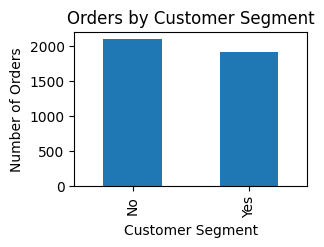

In [ ]:
 df1 = orders.merge(
    customers[["customer_id", "loyalty_member"]],
    on="customer_id")
 order_count = df1["loyalty_member"].value_counts()
 #loyal_members-rewards/discounts/benefits for repeat customers.
 print(order_count)
 plt.figure(figsize=(3,2))
 order_count.plot(kind="bar")

 plt.xlabel("Customer Segment")
 plt.ylabel("Number of Orders")
 plt.title("Orders by Customer Segment")
 plt.show()


**Business insight**

This tells the company that loyalty members are more active customers.

**What can the business do?**  
Give loyalty members special discounts.  
Give reward points for repeat purchases.  
Encourage non-loyalty customers to join the loyalty program.  
Send personalized offers to loyalty members.  

#2.Which cities generate the most orders?

In [ ]:
(customers['city'].value_counts()).sum()

np.int64(1200)

city     
Sheffield    555
Name: count, dtype: int64

 city      
Sheffield     555
Birmingham    554
Nottingham    528
Bristol       512
London        484
Liverpool     473
Leeds         464
Manchester    430
Name: count, dtype: int64


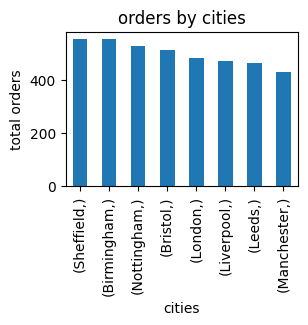

In [ ]:
df2=orders.merge(customers,on='customer_id')
order_count=df2[["city"]].value_counts()
order_count1=df2[["city"]].value_counts().head(1)
print(order_count1)
print("\n",order_count)
plt.figure(figsize=(3,2))
order_count.plot(kind='bar')
plt.xlabel('cities')
plt.ylabel('total orders')
plt.title('orders by cities')
plt.show()



**Business insight**  
Sheffield city generates most orders with (555),followed by Birmingham(554)
Manchester has the lowest number of orders(430)

**What can the business do**  
The business can focus on maintaining good inventory in high-order cities  
the company could investigate why demand is lower and consider local marketing offer discounts offers.



#3.Which product categories sell the most?

category
Beauty         1623
Clothing       2101
Electronics    1851
Home           3074
Sports         3250
Name: quantity, dtype: int64


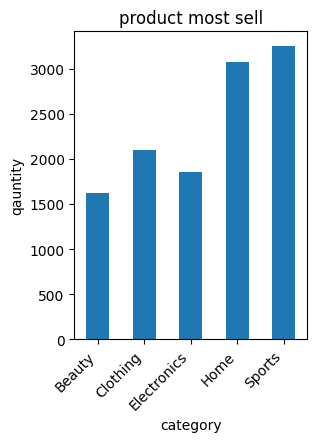

In [ ]:
df3 = orders.merge(
    products[["product_id", "category"]],
    on="product_id")
category_sales = df3.groupby("category")["quantity"].sum()
print(category_sales)
plt.figure(figsize=(3,4))
category_sales.plot(kind='bar')
plt.xlabel('category')
plt.ylabel('qauntity')
plt.title('product most sell')
plt.xticks(rotation=45,ha='right')
plt.show()

**Business insight**

Sports is the best-selling product category with 3,250 units sold, followed by Home with 3,074 units.

**What can the business do**  
Beauty has the lowest sales with 1,623 units.    
The business should maintain sufficient stock for Sports and Home   
while investigating ways to increase sales in the Beauty category
offer discounts


# 4.Which products are ordered the most?  


Products ordered:
product_name
Monitor 55              66
Bluetooth Speaker 18    64
Keyboard 38             62
USB Cable 65            60
Jacket 51               60
                        ..
Hair Dryer 35           37
Blender 80              37
USB Cable 50            37
Perfume 45              36
Blender 75              32
Name: count, Length: 80, dtype: int64

Total orders: 4000


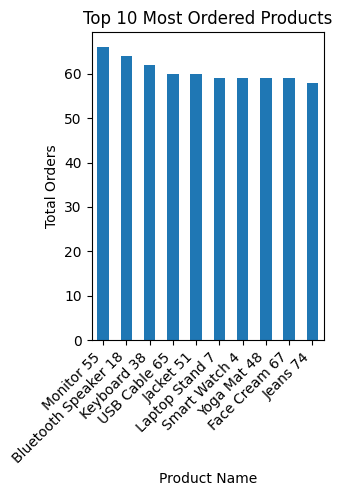

In [ ]:
df4 = orders.merge(
    products[["product_id", "product_name"]],
    on="product_id")
products_ordered = df4["product_name"].value_counts()
print("Products ordered:")
print(products_ordered)
print("\nTotal orders:", products_ordered.sum())
plt.figure(figsize=(3,4))
products_ordered.head(10).plot(kind="bar")
plt.xlabel("Product Name")
plt.ylabel("Total Orders")
plt.title("Top 10 Most Ordered Products")
plt.xticks(rotation=45, ha="right")
plt.show()

**Business Insight:**  
Monitor 55 is the most frequently ordered product with 66 orders, followed by Bluetooth Speaker 18 with 64 orders.

**What can the business do?**

Maintain sufficient stock of popular products.

Offer bundle deals on frequently ordered products.

Investigate low-demand products like Blender 75 (32 orders) and consider discounts to increase sales.

#5.Which payment method is associated with higher order quantities?  

payment_method
Card      3992
Cash      3939
Online    3968
Name: quantity, dtype: int64


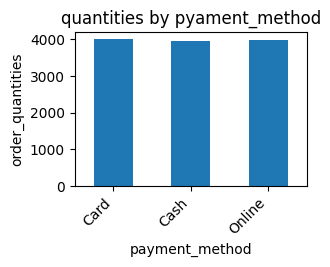

In [ ]:
higher_quantities=orders.groupby('payment_method',observed=False)['quantity'].sum()
print(higher_quantities)
plt.figure(figsize=(3,2))
higher_quantities.plot(kind='bar')
plt.xlabel('payment_method')
plt.ylabel('order_quantities')
plt.title('quantities by pyament_method')
plt.xticks(rotation=45,ha='right')
plt.show()

**Business Insight:**   
Card payments have the highest quantity (3,992), followed by Online (3,968) and Cash (3,939). The differences between payment methods are small.

**What can the business do?**

Continue supporting all three payment methods.

Offer online payment promotions to encourage purchases.

Monitor payment trends to understand customer preferences.

### **Outlier Analysis**

- `customers["age"]`
- `orders["quantity"]`
- `products["price"]`

In [ ]:
print(customers['age'].describe())
Q1 = customers["age"].quantile(0.25)
Q3 = customers["age"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = customers[
    (customers["age"] < lower) |
    (customers["age"] > upper)
]

print("Lower limit:", lower)
print("Upper limit:", upper)
print("Number of outliers:", len(outliers))

count    1200.000000
mean       41.615833
std        13.719515
min        18.000000
25%        30.000000
50%        41.000000
75%        54.000000
max        65.000000
Name: age, dtype: float64
Lower limit: -6.0
Upper limit: 90.0
Number of outliers: 0


In [ ]:
print(orders["quantity"].describe())
Q1=orders["quantity"].quantile(0.25)
Q3=orders["quantity"].quantile(0.75)

IQR=Q3-Q1

lower=Q1 - 1.5 * IQR
upper=Q3 + 1.5 * IQR

outliers=orders[(orders["quantity"]<lower)|
                (orders["quantity"]>upper)]

print("Lower limit:", lower)
print("Upper limit:", upper)
print("Number of outliers:", len(outliers))

count    4000.000000
mean        2.974750
std         1.411599
min         1.000000
25%         2.000000
50%         3.000000
75%         4.000000
max         5.000000
Name: quantity, dtype: float64
Lower limit: -1.0
Upper limit: 7.0
Number of outliers: 0


In [ ]:
print(products['price'].describe())
Q1=products['price'].quantile(0.25)
Q3=products['price'].quantile(0.75)

IQR=Q3-Q1

lower=Q1 - 1.5 * IQR
upper=Q3 + 1.5 * IQR

outliers=products[(products['price']<lower) |
                   (products['price']>upper)]

print("Lower limit:", lower)
print("Upper limit:", upper)
print("Number of outliers:", len(outliers))

count     80.000000
mean     140.082875
std       87.534130
min       11.070000
25%       58.922500
50%      126.115000
75%      214.132500
max      289.840000
Name: price, dtype: float64
Lower limit: -173.89249999999998
Upper limit: 446.9475
Number of outliers: 0


# **USING PANDAS** VS **SQL**

| Pandas Operation | SQL Equivalent |
| :--- | :--- |
| Filtering | `WHERE` |
| Selection | `SELECT` |
| GroupBy & Aggregations | `GROUP BY` & Aggregates (`SUM`, `AVG`, `COUNT`) |
| `value_counts()` | `GROUP BY ... COUNT(*)` |
| Sorting | `ORDER BY` |
| `unique()` / `nunique()` | `DISTINCT` / `COUNT(DISTINCT)` |


**pandas**

`filtering`    
1.Find customers whose age is between 25 and 35.   
2.Find customers who are Male and live in Manchester.        
3.Find orders where payment_method is Card.
4.Find products where price is greater than 200.  

In [ ]:
#filtering using pandas
print((customers["age"].between(25,35)).sum())
print(((customers["gender"]=="Male") & (customers["city"]=="Manchester")).sum())
print((products["price"]>200).sum())

269
71
27


In [ ]:
# SQL
print(len(customers.query("25 <= age <= 35")))
print(len(customers.query("gender == 'Male' and  city=='Manchester'")))
print(len(products.query("price>200")))

269
71
27


`selecting`  
1.Display only order_id, product_id, and quantity from orders.  
2.Display only product_name, category, and price from products.  
3.Display the first 10 rows containing only customer_id and gender.    

In [ ]:
#selecting
print(orders[["order_id","product_id","quantity"]])
print(products[["product_name","category","price"]])
print(customers[["customer_id","gender"]].head(10))

     order_id product_id  quantity
0      O00001       P006         4
1      O00002       P059         5
2      O00003       P030         1
3      O00004       P063         1
4      O00005       P032         2
...       ...        ...       ...
3995   O03996       P055         5
3996   O03997       P014         4
3997   O03998       P021         5
3998   O03999       P037         3
3999   O04000       P071         2

[4000 rows x 3 columns]
         product_name     category   price
0           Blender 1       Beauty  272.76
1           Perfume 2         Home  132.09
2      Water Bottle 3         Home   58.58
3       Smart Watch 4         Home  220.82
4           Perfume 5         Home   27.81
..                ...          ...     ...
75        Backpack 76  Electronics  218.72
76         Perfume 77     Clothing  151.88
77       USB Cable 78       Beauty  196.59
78  Vacuum Cleaner 79       Beauty  289.84
79         Blender 80  Electronics   20.74

[80 rows x 3 columns]
  customer_id  g

`value_counts()`  
1.Count customers by gender.  
2.Count customers by city.  
3.Count orders by payment method.  
4.Count products by category.  

In [ ]:
print(customers["gender"].value_counts())
print(customers["city"].value_counts())
print(orders["payment_method"].value_counts())
print(products["category"].value_counts())
# if we use normalize=True it gives in the form of percentage


gender
Male      613
Female    587
Name: count, dtype: int64
city
Sheffield     163
Nottingham    160
Birmingham    159
Bristol       156
London        146
Leeds         146
Liverpool     137
Manchester    133
Name: count, dtype: int64
payment_method
Cash      1362
Card      1345
Online    1293
Name: count, dtype: int64
category
Home           21
Sports         21
Clothing       15
Electronics    13
Beauty         10
Name: count, dtype: int64


`Groupby`  
1.Find average age by gender.  
2.Find total quantity by payment method.  
3.Find average product price by category.  
4.Find maximum product price by category.  

In [ ]:
print(customers.groupby("gender", observed=False)["age"].mean())
print("\n", orders.groupby("payment_method", observed=False)["quantity"].sum())
print("\n", products.groupby("category", observed=False)["price"].mean())
print("\n", products.groupby("category", observed=False)["price"].max())
#default behavior for categorical groupings put observed =false

gender
Female    41.069847
Male      42.138662
Name: age, dtype: float64

 payment_method
Card      3992
Cash      3939
Online    3968
Name: quantity, dtype: int64

 category
Beauty         149.125000
Clothing       152.900667
Electronics    112.048462
Home           155.406190
Sports         128.652857
Name: price, dtype: float64

 category
Beauty         289.84
Clothing       285.64
Electronics    253.94
Home           287.29
Sports         277.58
Name: price, dtype: float64


`Sorting`  
1.Sort customers by age from highest to lowest.  
2.Find the 5 most expensive products.  
3.Find the 5 cheapest products.  
4.Find orders with the highest quantity.  
5.find single most expensive product

In [ ]:
print(customers.sort_values(by="age", ascending=False))
print("\n",products.sort_values(by="product_name",ascending=False))
print("\n",products.sort_values(by="product_name",ascending=True))
print("\n",orders.sort_values(by="quantity",ascending=False))
print("\n",products.sort_values(by="product_name",ascending=False).head(1))

     customer_id  gender  age        city signup_date loyalty_member
1          C0002    Male   65  Manchester  2022-08-17            Yes
427        C0428  Female   65     Bristol  2022-06-06             No
468        C0469    Male   65  Birmingham  2022-02-16            Yes
394        C0395  Female   65      London  2023-02-25            Yes
436        C0437    Male   65       Leeds  2022-09-18            Yes
...          ...     ...  ...         ...         ...            ...
595        C0596    Male   18   Liverpool  2023-08-25            Yes
787        C0788    Male   18  Birmingham  2022-06-02             No
1111       C1112  Female   18  Nottingham  2022-01-04             No
474        C0475    Male   18   Sheffield  2022-03-18            Yes
850        C0851  Female   18  Birmingham  2023-11-25            Yes

[1200 rows x 6 columns]

    product_id product_name     category   price
61       P062  Yoga Mat 62     Clothing  213.02
52       P053  Yoga Mat 53     Clothing  137.77
4

`Unique / Distinct`  
1.Find unique cities.  
2.Count unique cities.  
3.Find unique payment methods.    
4.Count unique product categories.  

In [ ]:
print(customers["city"].unique())
print("\n",customers["city"].nunique())
print("\n",orders["payment_method"].unique())
print("\n",products["category"].nunique())

['Liverpool' 'Manchester' 'London' 'Nottingham' 'Sheffield' 'Bristol'
 'Leeds' 'Birmingham']

 8

 ['Card' 'Cash' 'Online']

 5


`Missing Values`   
1.Find customers where city is missing.  
2.Find orders where payment method is missing.  
3.Find products where price is missing.

In [ ]:
print(customers.isnull().sum())
print("\n","orders",":" ,orders["payment_method"].isnull().sum())
print("\n","products",":" ,products["price"].isnull().sum())

customer_id       0
gender            0
age               0
city              0
signup_date       0
loyalty_member    0
dtype: int64

 orders : 0

 products : 0


`Dates`  
1.Find customers who signed up in 2023.  
2.Find orders placed in 2024.  
3.Find the earliest order date.  
4.Count orders by year.  

In [ ]:
customers["signup_date"] = pd.to_datetime(customers["signup_date"])
orders["order_date"] = pd.to_datetime(orders["order_date"])

print((customers["signup_date"].dt.year == 2023).sum())
print("\n", "order_placed", ":", (orders["order_date"].dt.year == 2024).sum())
print("\n", "earlier_order_date", ":", orders["order_date"].min())
print("\n", "order_date_count", ":", orders["order_date"].dt.year.value_counts().sum())
print("\n", orders["order_date"].dt.year.value_counts())

594

 order_placed : 1149

 earlier_order_date : 2023-01-01 00:00:00

 order_date_count : 4000

 order_date
2023    2851
2024    1149
Name: count, dtype: int64


`Merge / JOIN`  
1.Combine orders with customers using customer_id.  
2.Combine orders with products using product_id.  
3.Find total quantity ordered by each customer.  
4.Find total quantity sold for each product.  

In [ ]:
print(orders.merge(customers,on="customer_id"))
print("\n",orders.merge(products,on="product_id"))
print("\n",orders.groupby("customer_id")["quantity"].sum())
print("\n",orders.groupby("product_id")["quantity"].sum())

## **probability**

Q1.
What is the probability that a randomly selected customer is a loyalty member?

In [ ]:
loyalty_count = (customers["loyalty_member"] == 'Yes').sum()
total_customers = len(customers)
probability = loyalty_count / total_customers
print("Loyalty members:", loyalty_count)
print("Total customers:", total_customers)
print("Probability:", probability)

#Loyalty: 47.5% of customers are members.

Loyalty members: 570
Total customers: 1200
Probability: 0.475


Q2.
What is the probability that a randomly selected order uses the Online payment method?

In [ ]:
online_payment=(orders['payment_method']=='Online').sum()
total_orders=len(orders)
probability=online_payment/total_orders
print("online_payment : ",online_payment)
print("total_orders :" ,total_orders)
print("probability :",probability)

#here is a 32.33% probability that a randomly selected order

online_payment :  1293
total_orders : 4000
probability : 0.32325


Q3.
What is the probability that a randomly selected product belongs to the Sports category?

In [ ]:
category_count=(products['category']=='Sports').sum()
total_products=len(products)
probability=category_count/total_products
print('category_count : ',category_count)
print('total_products : ',total_products)
print("probability : ",probability)

#There is a 26.25% probability that a randomly selected product

category_count :  21
total_products :  80
probability :  0.2625
